# AR(3): breakpoint selectors on population widths

This experiment uses the same 50 AR(3) coefficient vectors as the earlier empirical and padded-start experiments. It removes the simulated series and the empirical sphere optimizer from the input to the selectors.

For k = 1, 2, 3, all facet directions of a truncated support zonotope are evaluated globally. In dimension three, angular sweeps in the planes perpendicular to the generators evaluate all pairwise facet normals efficiently. The omitted impulse-response tail has an analytical bound at most 1e-8. The central reported estimate is the midpoint of the truncated minimum and that minimum plus the tail bound. For k >= 4, the population plateau is evaluated analytically as 2 / sqrt(1 + phi_1^2 + phi_2^2 + phi_3^2).

The angular-sweep argument is a derivation implemented in `ar_tools/population_widths.py`. Its results are checked against independent exhaustive enumeration on small examples. Floating-point operations are not interval certified; the tail bound controls truncation, and the recorded sweep residual checks rounding consistency.

The support formula and plateau are from Proposition `prop:minimum_width` in `Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex`, lines 270–299. The descent-chain and local-drift definitions follow the supplied PDF, pp. 5–8. No thesis files are edited.


In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = next(root for root in (Path.cwd(), *Path.cwd().parents)
                    if (root / "Code/Code_AR_processes/ar3_population_breakpoint_selectors.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from Code.Code_AR_processes.ar3_population_breakpoint_selectors import (
    run_experiment, DATA_DIR, IMAGE_DIR,
)


ERROR! Session/line number was not unique in database. History logging moved to new session 2


In [2]:
data_dir = run_experiment()


Selectors and truncation checks 10/50
Selectors and truncation checks 20/50
Selectors and truncation checks 30/50
Selectors and truncation checks 40/50
Selectors and truncation checks 50/50

Population results:
                            method  correct  under  over  total
                  First difference        9     41     0     50
                 Second difference       15     35     0     50
           Perron first difference        8     42     0     50
          Perron second difference       15     35     0     50
                     Descent chain       50      0     0     50
                       Local drift       50      0     0     50
               Drop-to-tail energy       50      0     0     50
                    Tail SSE ratio       50      0     0     50
               Tail variance ratio       50      0     0     50
Minimum width — first tied minimum       50      0     0     50

Maximum tail bound: 9.992140873328363e-09
Maximum angular-sweep roundoff residual: 8

## All 10 applicable width-based selectors

The comparison includes four derivative/spectral rules, descent chain, local drift, three cumulative-tail ratios, and the first tied minimum-width rule. Correct, underselected and overselected counts are shown for each method.

The inverse-matrix birth–death rule is undefined on an exact population plateau: its similarity matrix is singular and its reciprocal-drop transition rates are infinite. We therefore do not assign it a valid stationary-chain accuracy. BIC/PACF and residual/implied-innovation-width rules require time-series data or a different functional; they are not evaluated by substituting geometric population widths into them.


,correct,under,over,total
method,,,,
First difference,9,41,0,50
Second difference,15,35,0,50
Perron first difference,8,42,0,50
Perron second difference,15,35,0,50
Descent chain,50,0,0,50
Local drift,50,0,0,50
Drop-to-tail energy,50,0,0,50
Tail SSE ratio,50,0,0,50
Tail variance ratio,50,0,0,50


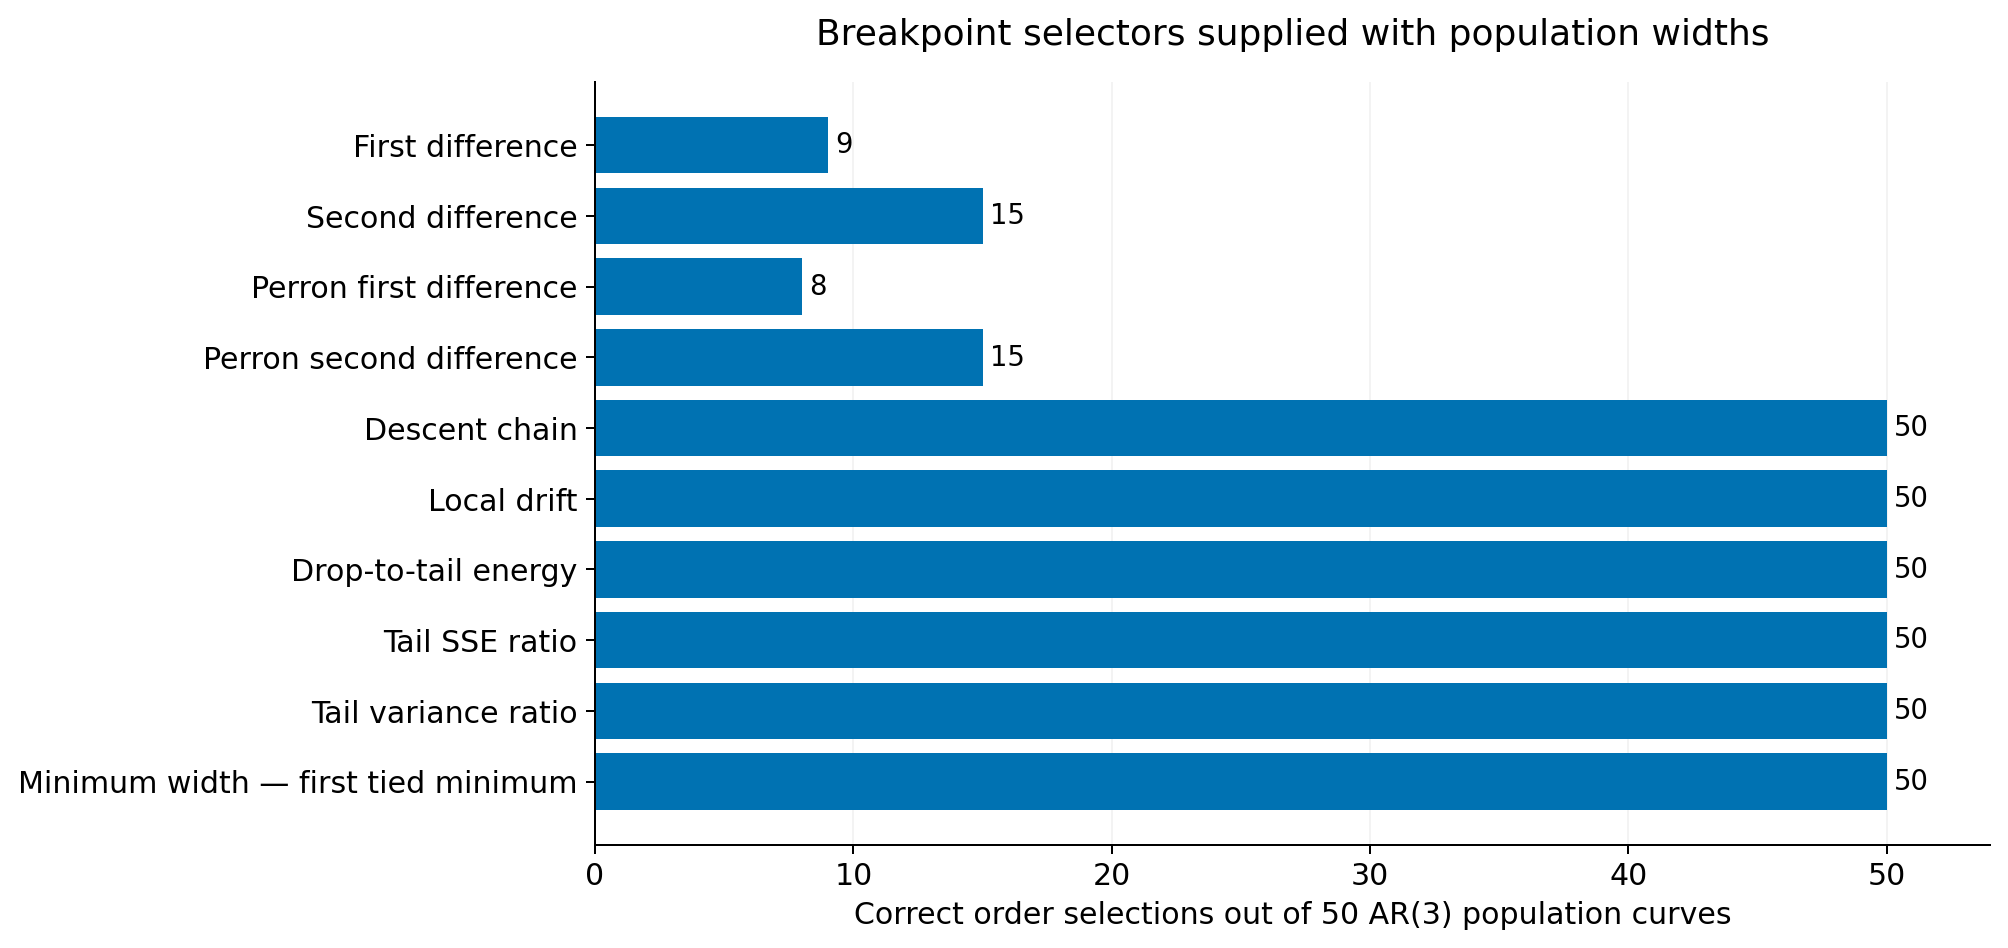

In [3]:
summary = pd.read_csv(DATA_DIR / "summary.csv")
display(summary.set_index("method"))
display(Image(filename=str(IMAGE_DIR / "population_selector_accuracy.png")))


## Population versus empirical results

The common methods below use the same coefficient vectors. Empirical results are from the previous padded-start rerun; population results use globally evaluated truncated support widths and an analytical plateau. This comparison distinguishes selector failure on ideal population input from finite-sample and numerical width-estimation effects.


,correct_population,correct_warm_empirical
method,,
First difference,9,9.0
Second difference,15,15.0
Perron first difference,8,8.0
Perron second difference,15,12.0
Descent chain,50,19.0
Local drift,50,NaN
Drop-to-tail energy,50,NaN
Tail SSE ratio,50,NaN
Tail variance ratio,50,NaN


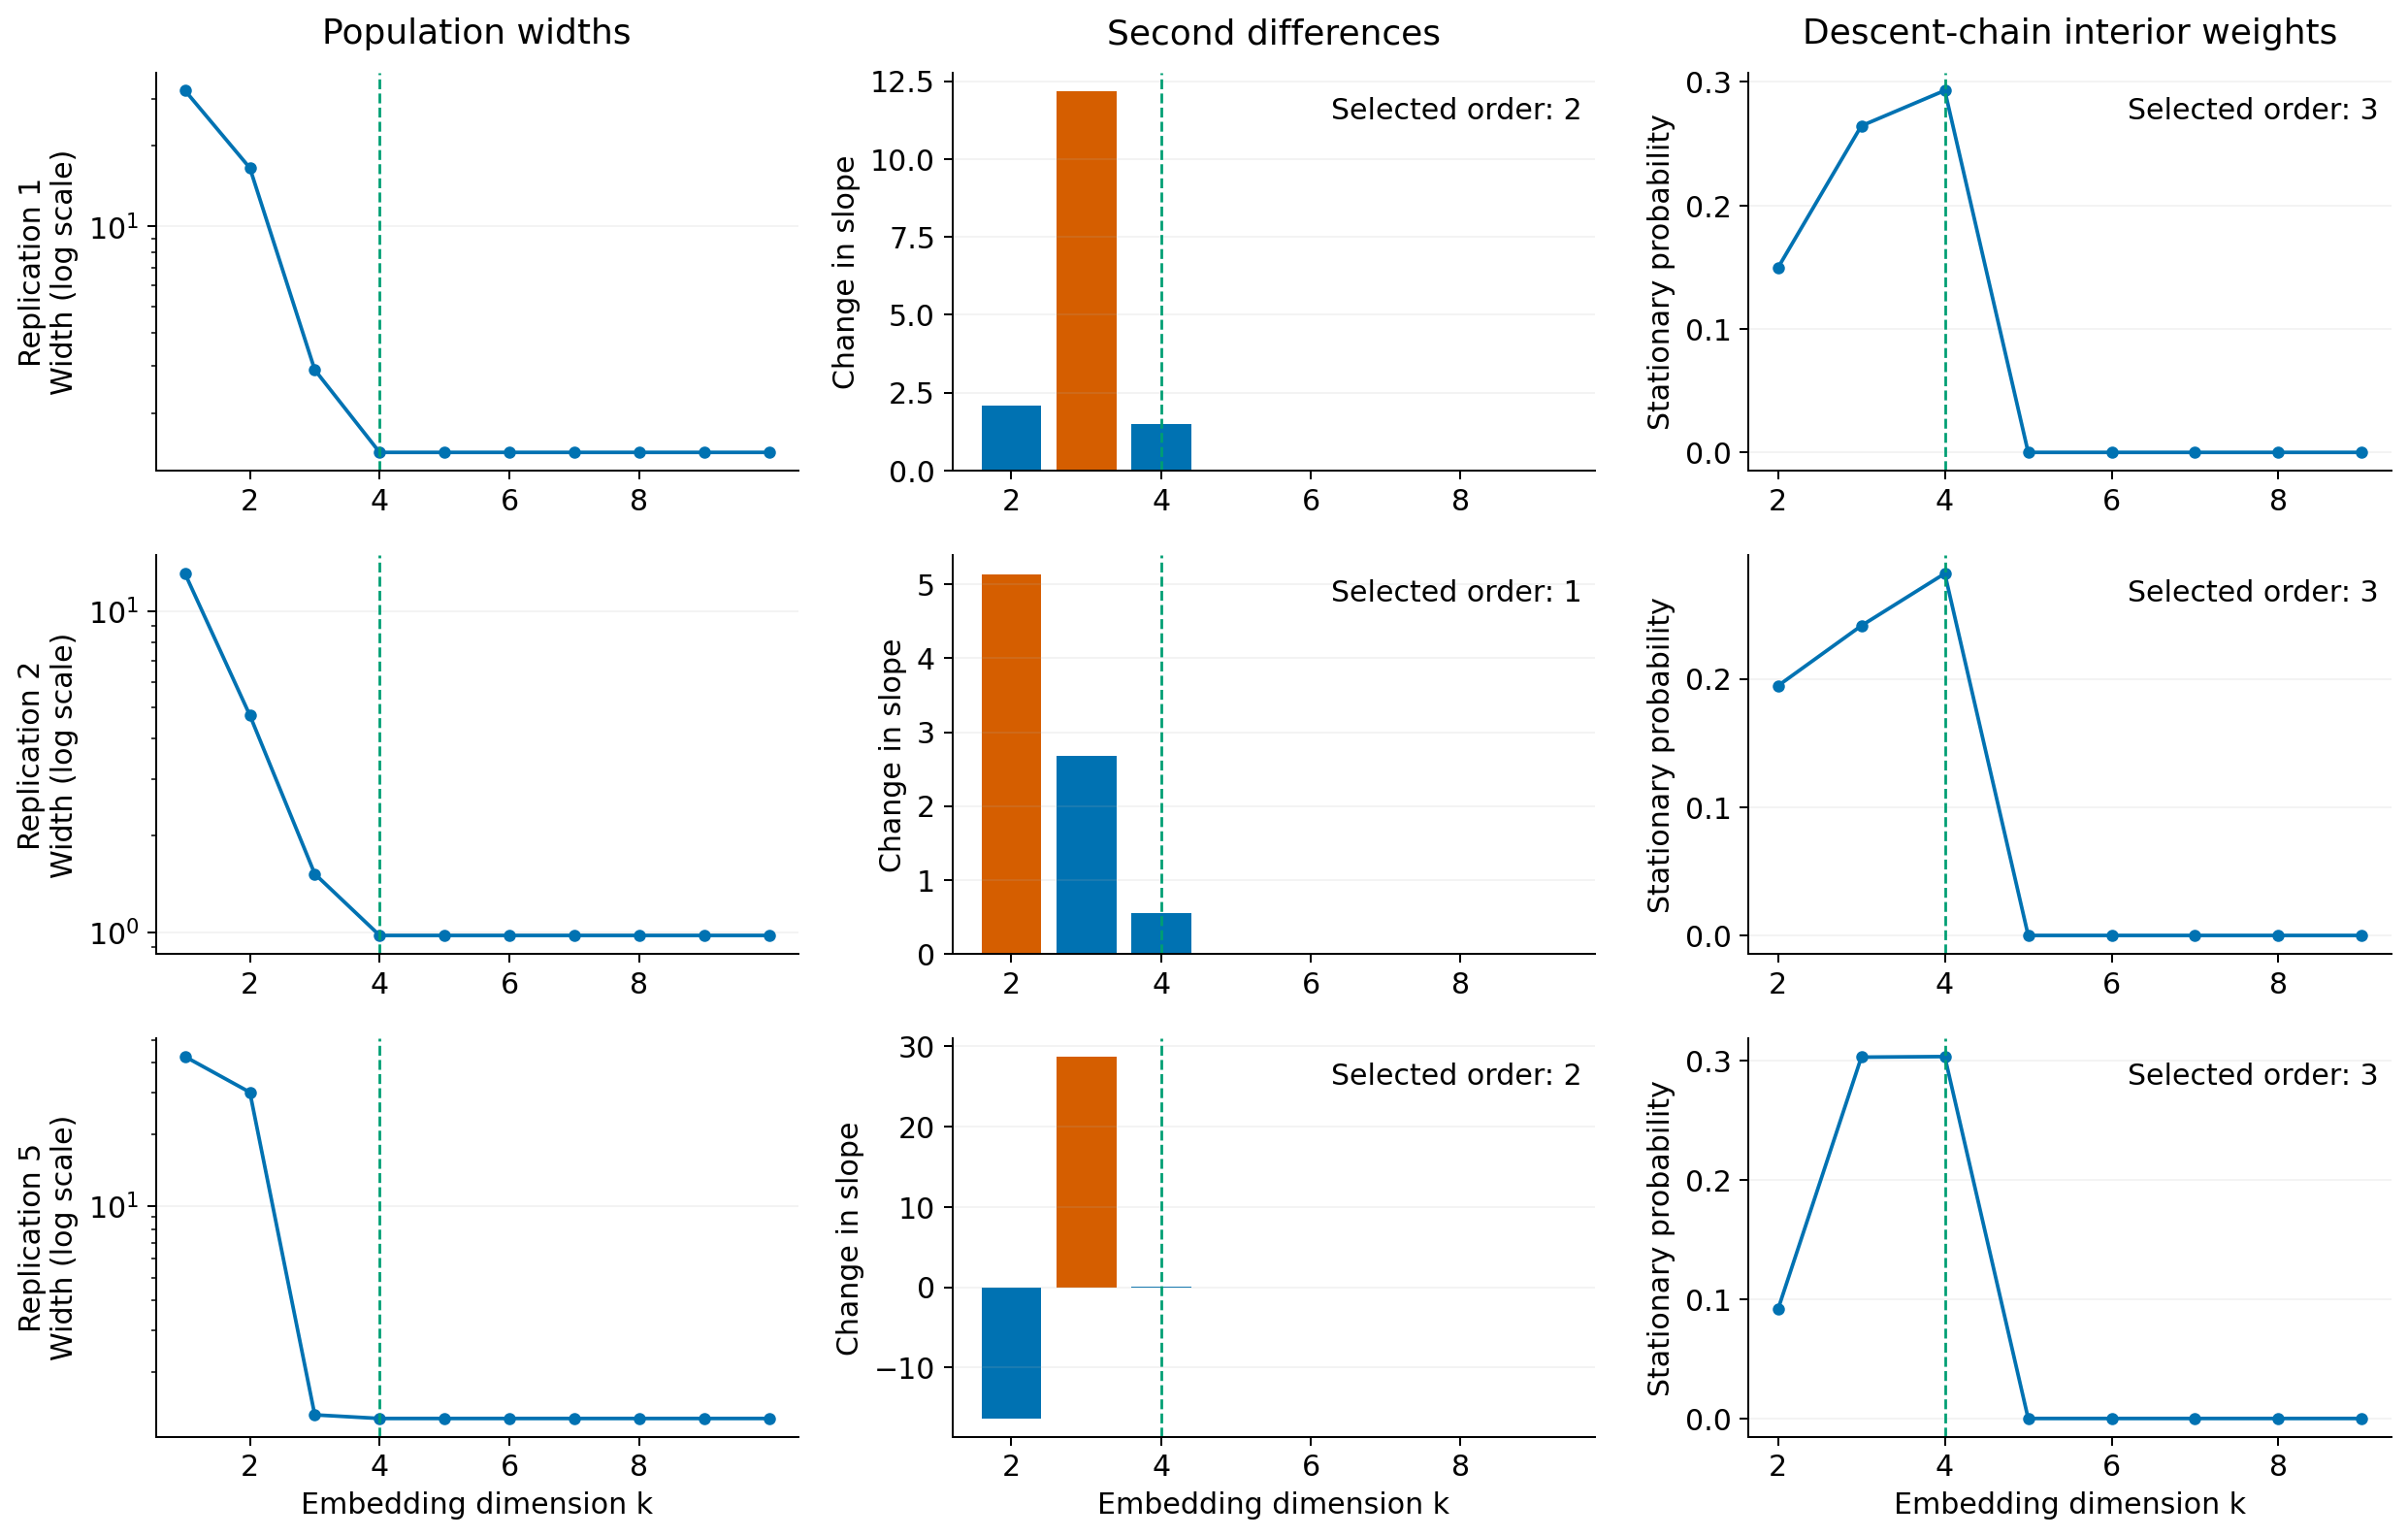

In [4]:
comparison = pd.read_csv(DATA_DIR / "population_vs_warm_empirical.csv")
display(comparison[["method", "correct_population", "correct_warm_empirical"]].set_index("method"))
display(Image(filename=str(IMAGE_DIR / "population_examples.png")))


## Truncation sensitivity

All eight corners of the three pre-plateau truncation intervals are tested for every selector and process. Stability at these corners is a sensitivity check, not a proof over the entire interval. Exact analytical plateau entries are held fixed.



In [5]:
widths = pd.read_csv(DATA_DIR / "population_width_curves.csv")
checks = pd.read_csv(DATA_DIR / "truncation_corner_checks.csv")
print("Population curves:", widths.replication.nunique())
print("Largest omitted-tail bound:", widths.tail_error_bound.max())
print("Largest angular-sweep residual:", widths.maximum_sweep_roundoff_residual.max())
print("Unstable process/method corner checks:", int((~checks.stable_at_all_eight_corners).sum()))
assert widths.tail_error_bound.max() <= 1e-8
assert checks.stable_at_all_eight_corners.all()


Population curves: 50
Largest omitted-tail bound: 9.992140873328365e-09
Largest angular-sweep residual: 8.513856286640475e-12
Unstable process/method corner checks: 0


## Saved artifacts

The CSV folder contains all population curves, per-process widths and directions, selections, cumulative-chain scores, truncation checks, and the comparison with the earlier numerical population cache. All displayed figures have PDF copies under `outputs/pdfs/ar3_population_breakpoint_selectors/`.

The main empirical conclusion is limited to these 50 coefficient vectors. Population success does not establish finite-sample consistency without the additional assumptions required by the particular selector. The derivative rules remain fallible even after empirical width estimation is removed from this comparison.
